# Chapter 9: Text Processing and Multiclass Classification

This notebook covers Chapter 9 of *scikit-learn Cookbook* (3rd Edition, Packt). Machine learning models need numbers, but much real-world data is text: emails, reviews, articles, and messages. This chapter shows how to turn text into numeric features and how to classify documents into more than two categories.

**Topics covered:**
- Bag-of-words with `CountVectorizer`
- Stop words, n-grams, and vocabulary control
- TF-IDF weighting with `TfidfVectorizer`
- `HashingVectorizer` for large or streaming text
- Text classification pipelines (Naive Bayes, logistic regression, linear SVM)
- Multiclass strategies: native, One-vs-Rest, One-vs-One, and output codes
- Evaluating multiclass models: confusion matrix, macro and micro averages
- Tuning a text pipeline with `GridSearchCV`

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import (CountVectorizer, TfidfVectorizer,
                                             TfidfTransformer, HashingVectorizer)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier, OutputCodeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             f1_score, accuracy_score)

## 1. From Text to Numbers: Bag-of-Words

The simplest way to represent text is the **bag-of-words** model:
1. Build a **vocabulary** of all words that appear in the training documents.
2. Represent each document as a vector of **word counts**, one position per vocabulary word.

Word order is ignored ("dog bites man" and "man bites dog" get the same vector), but the approach works surprisingly well for classification. Because most documents contain only a small part of the vocabulary, the result is stored as a **sparse matrix** (only non-zero values are saved).

`CountVectorizer` performs **tokenization** (splitting text into words), lowercasing, and counting.

In [2]:
corpus = [
    'The cat sat on the mat.',
    'The dog sat on the log.',
    'Cats and dogs are great pets.',
    'I love my cat and my dog!',
]

cv = CountVectorizer()
X_counts = cv.fit_transform(corpus)

print('Vocabulary size:', len(cv.vocabulary_))
print('Matrix type:', type(X_counts).__name__, X_counts.shape)
pd.DataFrame(X_counts.toarray(), columns=cv.get_feature_names_out(),
             index=[f'doc{i}' for i in range(len(corpus))])

Vocabulary size: 15
Matrix type: csr_matrix (4, 15)


,and,are,cat,cats,dog,dogs,great,log,love,mat,my,on,pets,sat,the
doc0,0,0,1,0,0,0,0,0,0,1,0,1,0,1,2
doc1,0,0,0,0,1,0,0,1,0,0,0,1,0,1,2
doc2,1,1,0,1,0,1,1,0,0,0,0,0,1,0,0
doc3,1,0,1,0,1,0,0,0,1,0,2,0,0,0,0


Each row is a document and each column a word from the vocabulary. Notice that "cat" and "cats" are separate columns, and common words like "the" get high counts even though they say little about the topic.

## 2. Stop Words, n-grams, and Vocabulary Control

`CountVectorizer` has parameters to make the features more useful:
- `stop_words='english'`: removes very common words (the, and, on) that carry little meaning.
- `ngram_range=(1, 2)`: adds **bigrams** (pairs of consecutive words), which keep some word order, e.g. "not good" vs. "good".
- `min_df` / `max_df`: ignore words that appear in too few documents (rare typos) or too many (near stop words).
- `max_features`: keep only the most frequent terms.

In [3]:
cv2 = CountVectorizer(stop_words='english', ngram_range=(1, 2))
X2 = cv2.fit_transform(corpus)

print('Vocabulary size with stop words removed + bigrams:', len(cv2.vocabulary_))
print(cv2.get_feature_names_out())

Vocabulary size with stop words removed + bigrams: 19
['cat' 'cat dog' 'cat sat' 'cats' 'cats dogs' 'dog' 'dog sat' 'dogs'
 'dogs great' 'great' 'great pets' 'log' 'love' 'love cat' 'mat' 'pets'
 'sat' 'sat log' 'sat mat']


Stop words such as "the" and "on" are gone, and bigrams like "cat sat" and "love cat" were added. Bigrams increase the vocabulary quickly, which is why `min_df` and `max_features` are useful on real datasets.

## 3. TF-IDF Weighting

Raw counts treat every word equally. **TF-IDF** (Term Frequency, Inverse Document Frequency) gives more weight to words that are frequent in a document but **rare across the collection**, since these are the most distinctive:

$$\text{tfidf}(t, d) = \text{tf}(t, d) \times \text{idf}(t), \qquad \text{idf}(t) = \ln\frac{1 + n}{1 + \text{df}(t)} + 1$$

where $n$ is the number of documents and $\text{df}(t)$ the number of documents containing term $t$. By default each document vector is then L2-normalized, so long and short documents are comparable.

In [4]:
tfidf = TfidfVectorizer(stop_words='english')
X_tfidf = tfidf.fit_transform(corpus)

idf = pd.Series(tfidf.idf_, index=tfidf.get_feature_names_out()).sort_values()
print('IDF values (lower = more common across documents):')
print(idf.round(3))

pd.DataFrame(X_tfidf.toarray().round(3), columns=tfidf.get_feature_names_out())

IDF values (lower = more common across documents):
cat      1.511
dog      1.511
sat      1.511
cats     1.916
great    1.916
log      1.916
love     1.916
dogs     1.916
mat      1.916
pets     1.916
dtype: float64


,cat,cats,dog,dogs,great,log,love,mat,pets,sat
0,0.526,0.0,0.000,0.0,0.0,0.000,0.000,0.668,0.0,0.526
1,0.000,0.0,0.526,0.0,0.0,0.668,0.000,0.000,0.0,0.526
2,0.000,0.5,0.000,0.5,0.5,0.000,0.000,0.000,0.5,0.000
3,0.526,0.0,0.526,0.0,0.0,0.000,0.668,0.000,0.0,0.000


Words that appear in several documents (such as "cat" and "dog") get a lower IDF, while words that appear in only one document get the highest IDF. As a result, each document's most distinctive words receive the largest TF-IDF weights.

## 4. A Real Dataset: 20 Newsgroups

The **20 Newsgroups** dataset contains about 18,000 forum posts from 20 topics. Four topics are used here to keep training fast. Headers, signatures, and quoted replies are removed so the model must learn from the actual message content rather than metadata.

In [5]:
categories = ['rec.sport.hockey', 'sci.space', 'comp.graphics', 'talk.politics.mideast']
remove = ('headers', 'footers', 'quotes')

train = fetch_20newsgroups(subset='train', categories=categories, remove=remove, random_state=42)
test = fetch_20newsgroups(subset='test', categories=categories, remove=remove, random_state=42)

print('Training documents:', len(train.data))
print('Test documents:    ', len(test.data))
print('Classes:', train.target_names)
print('\nClass counts (train):', np.bincount(train.target))
print('\nExample post:\n', train.data[0][:400])

Training documents: 2341
Test documents:     1558
Classes: ['comp.graphics', 'rec.sport.hockey', 'sci.space', 'talk.politics.mideast']

Class counts (train): [584 600 593 564]

Example post:
 : 8~> I require BGI drivers for Super VGA Displays and Super XVGA Displays. Does 
: 8~> anyone know where I could obtain the relevant drivers ? (FTP sites ??)

: 	I would like to know too!

: Regards,
: Dominic

garbo.uwasa.fi (or one of its many mirrors) has a file
called "svgabg40" in the programming subdirectory.
These are svga bgi drivers for a variety of cards.

[from the README]:
"Card types


The four classes are roughly balanced, and each post is free-form text. This is a **multiclass** problem: every document belongs to exactly one of four topics.

## 5. Text Classification Pipelines

A text pipeline chains the vectorizer and the classifier, so the vocabulary and IDF values are learned from the training data only. Three common classifiers for text:
- **Multinomial Naive Bayes**: models word counts per class using Bayes' theorem, assuming words are independent given the class. Very fast and a strong baseline.
- **Logistic regression**: a linear model with probability outputs.
- **Linear SVM** (`LinearSVC`): often the most accurate linear model for high-dimensional sparse text.

In [6]:
pipelines = {
    'Naive Bayes': make_pipeline(TfidfVectorizer(stop_words='english', min_df=2),
                                 MultinomialNB(alpha=0.1)),
    'Logistic Regression': make_pipeline(TfidfVectorizer(stop_words='english', min_df=2),
                                         LogisticRegression(max_iter=2000)),
    'Linear SVM': make_pipeline(TfidfVectorizer(stop_words='english', min_df=2),
                                LinearSVC()),
}

for name, pipe in pipelines.items():
    start = time.perf_counter()
    pipe.fit(train.data, train.target)
    pred = pipe.predict(test.data)
    print(f'{name:>20}: accuracy = {accuracy_score(test.target, pred):.3f}, '
          f'macro F1 = {f1_score(test.target, pred, average="macro"):.3f}, '
          f'time = {time.perf_counter() - start:.1f} s')

         Naive Bayes: accuracy = 0.917, macro F1 = 0.917, time = 0.7 s
 Logistic Regression: accuracy = 0.912, macro F1 = 0.913, time = 0.8 s
          Linear SVM: accuracy = 0.908, macro F1 = 0.909, time = 0.6 s


All three models classify the posts well, even though they only see word weights. Naive Bayes is the fastest, while the linear SVM and logistic regression are typically a little more accurate. For text, linear models work well because the data has many features (thousands of words) and classes are often close to linearly separable in that space.

### 5.1 What Did the Model Learn?

For linear models, each class has a weight per word. The words with the highest weights are the strongest signals for that class.

In [7]:
svm_pipe = pipelines['Linear SVM']
vec = svm_pipe.named_steps['tfidfvectorizer']
svm = svm_pipe.named_steps['linearsvc']
words = vec.get_feature_names_out()

for i, cls in enumerate(train.target_names):
    top = np.argsort(svm.coef_[i])[-8:][::-1]
    print(f'{cls:>22}: {", ".join(words[top])}')

         comp.graphics: graphics, image, computer, file, 3d, hi, virtual, package
      rec.sport.hockey: hockey, game, team, season, mask, games, nhl, puck
             sci.space: space, orbit, nasa, moon, launch, spacecraft, shuttle, solar
 talk.politics.mideast: israel, israeli, loser, jews, jewish, turkish, mr, arab


The top words for each topic make intuitive sense (for example, hockey terms for the hockey group and space terms for the space group). This shows that the model's decisions are interpretable: it relies on topic-specific vocabulary.

## 6. Evaluating Multiclass Models

For multiclass problems, precision, recall, and F1 are computed **per class** and then averaged:
- **Macro average**: the simple mean over classes, treating every class equally (important when small classes matter).
- **Weighted average**: the mean weighted by the number of samples in each class.
- **Micro average**: computed from the total TP, FP, and FN over all classes (equal to accuracy for single-label problems).

The **confusion matrix** shows which classes are confused with each other.

                       precision    recall  f1-score   support

        comp.graphics       0.91      0.90      0.90       389
     rec.sport.hockey       0.95      0.92      0.93       399
            sci.space       0.84      0.89      0.87       394
talk.politics.mideast       0.94      0.92      0.93       376

             accuracy                           0.91      1558
            macro avg       0.91      0.91      0.91      1558
         weighted avg       0.91      0.91      0.91      1558



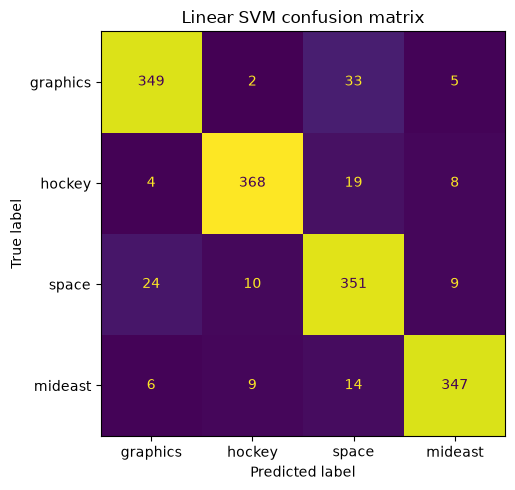

In [8]:
pred = svm_pipe.predict(test.data)
print(classification_report(test.target, pred, target_names=train.target_names))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(test.target, pred,
                                        display_labels=[n.split('.')[-1] for n in train.target_names],
                                        ax=ax, colorbar=False)
ax.set_title('Linear SVM confusion matrix')
plt.tight_layout()
plt.show()

Most posts lie on the diagonal (correct predictions). The remaining errors usually come from posts that are very short or that mention words common to several topics. The per-class report helps spot whether one topic is systematically harder than the others.

## 7. Multiclass Strategies

Some algorithms handle multiple classes natively (Naive Bayes, decision trees, multinomial logistic regression). Others are binary at heart and need a strategy:
- **One-vs-Rest (OvR)**: train $K$ binary classifiers, each separating one class from all others. Predict the class with the highest score.
- **One-vs-One (OvO)**: train a classifier for every pair of classes, $\frac{K(K-1)}{2}$ in total, and use a majority vote. Each model is trained on less data, which helps algorithms that scale badly with sample size.
- **Error-Correcting Output Codes**: assign each class a binary code and train one classifier per code bit. Prediction picks the class whose code is closest, which can correct some individual classifier mistakes.

In [9]:
X_train_vec = TfidfVectorizer(stop_words='english', min_df=2).fit(train.data)
Xtr = X_train_vec.transform(train.data)
Xte = X_train_vec.transform(test.data)

strategies = {
    'One-vs-Rest': OneVsRestClassifier(LinearSVC()),
    'One-vs-One': OneVsOneClassifier(LinearSVC()),
    'Output codes': OutputCodeClassifier(LinearSVC(), code_size=2, random_state=42),
}
K = len(train.target_names)
for name, clf in strategies.items():
    clf.fit(Xtr, train.target)
    n_models = len(clf.estimators_)
    print(f'{name:>13}: {n_models} binary models, '
          f'accuracy = {clf.score(Xte, test.target):.3f}')
print(f'\nWith K = {K} classes: OvR needs {K} models, OvO needs {K * (K - 1) // 2}.')

  One-vs-Rest: 4 binary models, accuracy = 0.908
   One-vs-One: 6 binary models, accuracy = 0.909
 Output codes: 8 binary models, accuracy = 0.905

With K = 4 classes: OvR needs 4 models, OvO needs 6.


All three strategies reach similar accuracy on this problem. The difference is in the number and size of the models: OvR trains one model per class, OvO trains one per pair of classes (more models, each on less data), and output codes trade the number of models against robustness to individual errors.

## 8. HashingVectorizer for Large-Scale Text

`CountVectorizer` and `TfidfVectorizer` store the whole vocabulary in memory, which becomes a problem for very large or streaming text collections. `HashingVectorizer` instead maps each word to a column using a **hash function**:
- No vocabulary is stored, so memory use is fixed and new documents can be processed at any time.
- Different words can occasionally map to the same column (**hash collisions**).
- The original words cannot be recovered from the column indices, so the model is less interpretable.

In [10]:
hash_pipe = make_pipeline(HashingVectorizer(n_features=2**18, stop_words='english',
                                            alternate_sign=False),
                          TfidfTransformer(),
                          LinearSVC())
hash_pipe.fit(train.data, train.target)
print(f'HashingVectorizer + TF-IDF + LinearSVC accuracy: {hash_pipe.score(test.data, test.target):.3f}')

HashingVectorizer + TF-IDF + LinearSVC accuracy: 0.909


The hashing pipeline reaches accuracy close to the vocabulary-based pipeline while using a fixed number of columns, which makes it suitable for very large datasets and online learning.

## 9. Tuning a Text Pipeline

Vectorizer settings are hyperparameters too. `GridSearchCV` can tune the vectorizer and the classifier together, using the `step__parameter` naming convention.

In [11]:
pipe = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english')),
    ('clf', LinearSVC()),
])
param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [1, 3],
    'clf__C': [0.1, 1, 10],
}
grid = GridSearchCV(pipe, param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
grid.fit(train.data, train.target)

print('Best parameters:', grid.best_params_)
print(f'Best CV macro F1: {grid.best_score_:.3f}')
print(f'Test macro F1:    {f1_score(test.target, grid.predict(test.data), average="macro"):.3f}')

Best parameters: {'clf__C': 1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}
Best CV macro F1: 0.908
Test macro F1:    0.918


The grid search compares unigrams vs. unigrams plus bigrams, different minimum document frequencies, and different regularization strengths. Because the vectorizer is inside the pipeline, it is refitted on each training fold, so the cross-validation estimate is not affected by data leakage.

## Chapter Summary

- Text is turned into numbers with the **bag-of-words** model, producing sparse document-term matrices.
- `CountVectorizer` controls tokenization, **stop words**, **n-grams**, and vocabulary size (`min_df`, `max_df`, `max_features`).
- **TF-IDF** gives more weight to distinctive words and less to words common across documents.
- `HashingVectorizer` avoids storing a vocabulary, which suits very large or streaming text, at the cost of interpretability.
- **Naive Bayes**, **logistic regression**, and **linear SVMs** are strong, fast classifiers for high-dimensional text.
- Multiclass problems are solved natively or with **One-vs-Rest**, **One-vs-One**, or **output codes**.
- Multiclass evaluation uses per-class metrics with **macro**, **weighted**, and **micro** averages, plus the confusion matrix.
- Vectorizer and classifier settings should be tuned together inside a pipeline with `GridSearchCV`.